# Numpy

**Reference for numpy**
1. [Official Document](https://numpy.org/doc/stable/reference/arrays.html)
2. [Python Data Science Handbook
](https://jakevdp.github.io/PythonDataScienceHandbook/02.00-introduction-to-numpy.html)
3. [Numpy cheat sheet](https://www.datacamp.com/cheat-sheet/numpy-cheat-sheet-data-analysis-in-python)

***"No matter what the data are, the first step in making it analyzable will be to transform them into arrays of numbers"***

In [1]:
import numpy as np

import matplotlib.pyplot as plt
import random # Thư viện built-in của Python 

Kiểm tra cài đặt numpy

In [2]:
np.__version__

'1.26.0'

## 1. Tại sao lại cần Numpy

Nhân 2 ma trận bằng Python list + vòng lặp:

In [3]:
# Tạo 2 ma trận có kích thước 300x200 và 200x300
nrows1 = 300; ncols1 = nrows2 = 200; ncols2 = 300
m1_list = []
for r in range(nrows1):
    row_vals = []
    for c in range(ncols1):
        row_vals.append(random.randint(-100, 100))
    m1_list.append(row_vals)
    
m2_list = []
for r in range(nrows2):
    row_vals = []
    for c in range(ncols2):
        row_vals.append(random.randint(-100, 100))
    m2_list.append(row_vals)
    
print(len(m1_list), len(m1_list[0]))
print(len(m2_list), len(m2_list[0]))

300 200
200 300


In [4]:
%%time
# Nhân 2 ma trận
m3_list = []
for r in range(nrows1):
    row_vals = []
    for c in range(ncols2):
        temp = 0
        for i in range(ncols1):
            temp += m1_list[r][i] * m2_list[i][c]
        row_vals.append(temp)
    m3_list.append(row_vals)

CPU times: user 1.85 s, sys: 0 ns, total: 1.85 s
Wall time: 1.85 s


Nhân 2 ma trận bằng Numpy array + toán tử nhân ma trận của Numpy:

In [5]:
m1_array = np.array(m1_list)
m2_array = np.array(m2_list)

In [6]:
%%time
m3_array = m1_array @ m2_array

CPU times: user 9.34 ms, sys: 0 ns, total: 9.34 ms
Wall time: 9.15 ms


So sánh 2 cách làm:

- Thời gian viết code: ...
- Thời gian chạy: ...
- Kết quả: ...

In [7]:
# m3_list có bằng m3_array không?
np.all(np.array(m3_list) == m3_array)

True

## 2. Numpy cơ bản

## Tạo Numpy array & xem thông tin của Numpy array 

In [8]:
# Tạo 1D array từ list
a = np.array([5, 6, 7, 8], dtype='float')
a

array([5., 6., 7., 8.])

In [9]:
# Tạo 2D array từ list
b = np.array([[5, 6, 7, 8], [9, 0, 1, 2]])
b

array([[5, 6, 7, 8],
       [9, 0, 1, 2]])

In [10]:
# Xem các thông tin của array
print('Số chiều:', b.ndim)
print('Số lượng phần tử của mỗi chiều:', b.shape)
print('Tổng số lượng phần tử:', b.size)
print('Kiểu dữ liệu của mỗi phần tử:', b.dtype)
print('Kích thước (byte) của mỗi phần tử:', b.itemsize)
print('Tổng kích thước (byte):', b.nbytes)

Số chiều: 2
Số lượng phần tử của mỗi chiều: (2, 4)
Tổng số lượng phần tử: 8
Kiểu dữ liệu của mỗi phần tử: int64
Kích thước (byte) của mỗi phần tử: 8
Tổng kích thước (byte): 64


In [11]:
# Tạo ra array toàn với cùng một giá trị, chẳng hạn 0
a = np.full((2,3),0) # Shortcut: np.zeros((2,3)) (cũng có np.ones)
a

array([[0, 0, 0],
       [0, 0, 0]])

In [12]:
# Tạo ra array gồm các số được phát sinh ngẫu nghiên
# Ví dụ, số nguyên được phát sinh theo phân bố đều trong [0, 10)   
a = np.random.randint(0, 10, (2, 3))
a

array([[0, 9, 9],
       [6, 0, 6]])

In [13]:
# Tạo ra array rỗng (không khởi tạo giá trị)
a = np.empty((2, 3))
a

array([[4.96470324e-310, 0.00000000e+000, 1.58101007e-322],
       [1.63041663e-322, 4.96416106e-310, 6.70143098e-310]])

In [14]:
# Tạo ra ma trận đơn vị (identity matrix)
a = np.eye(3)
a

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

In [15]:
# Tạo ra array gồm các số cách đều nhau
# Ví dụ, array gồm: 1, 1.5, 2, 2.5, ..., 5
# Cách 1: chỉ định đầu, cuối, và bước nhảy
a = np.arange(1, 5.1, 0.5)
a

array([1. , 1.5, 2. , 2.5, 3. , 3.5, 4. , 4.5, 5. ])

In [16]:
# Tạo ra array gồm các số cách đều nhau
# Ví dụ, array gồm: 1, 1.5, 2, 2.5, ..., 5
# Cách 2: chỉ định đầu, cuối, và số lượng phần tử
a = np.linspace(1, 5, 9)
a

array([1. , 1.5, 2. , 2.5, 3. , 3.5, 4. , 4.5, 5. ])

In [17]:
# Tạo ra array từ một array khác bằng cách thay đổi shape
a = np.arange(6)
print(a)
b = a.reshape((2, 3), order='C')
print()
print(b)

[0 1 2 3 4 5]

[[0 1 2]
 [3 4 5]]


`b` trỏ tới một array object khác với `a`:

In [18]:
b is a

False

Nếu object mà `b` trỏ tới hoàn toàn độc lập với object mà `a` trỏ tới thì `b` được gọi là một copy (deep copy) của `a` $\to$ khi thay đổi dữ liệu ở `b` (ví dụ, cho `b[0, 0] = 99`) thì không làm ảnh hưởng đến dữ liệu ở `a`.

Còn nếu object mà `b` trỏ tới dùng chung dữ liệu (một object có khá nhiều thành phần, trong đó có dữ liệu) với object mà `a` trỏ tới thì `b` được gọi là view (shallow copy) của `a` $\to$ khi thay đổi dữ liệu ở `b` thì sẽ làm thay đổi dữ liệu ở `a`.

Ở đây, `b` là có được bằng cách reshape `a`. Vậy `b` là copy hay là view của `a`?

Một cách là kiểm tra `b.flags.owndata`. Nếu kết quả là True thì có nghĩa là `b` có dữ liệu độc lập của `b`, tức `b` là copy của `a`; ngược lại `b` là view của `a`.

In [19]:
print(a.flags.owndata)
print(b.flags.owndata)

True
False


In [20]:
b[0, 0] = 99
a

array([99,  1,  2,  3,  4,  5])

**Các kiểu dữ liệu của numpy**

| dtype | Range / precision |
|---|---|
| `bool` | True / False, stored in 1 byte |
| `int8`, `int16`, `int32`, `int64` | signed integers; `int8` is −128…127 |
| `uint8`, `uint16`, … | unsigned integers; `uint8` is 0…255 (image pixels) |
| `float16`, `float32`, `float64` | floating point; `float64` (the default) has ~15–16 significant digits |
| `complex64`, `complex128` | complex numbers |

> **NumPy 2 note:** the old aliases `np.float_`, `np.complex_` were removed. Write `np.float64`, `np.complex128`, or just `float`.

In [21]:
# Tạo array từ file
# File 'P4DS-Grades.csv' chứa điểm môn này của khóa trước ;-)
# 3 cột đầu ứng với điểm 3 HW (mỗi HW chiếm 50%/3 tổng điểm)
# cột cuối ứng điểm đồ án cuối kỳ (chiếm 50% tổng điểm)
p4ds_grades = np.genfromtxt('Data/P4DS-Grades.csv', 
                            delimiter=',', skip_header=1)
p4ds_grades

array([[ 0.  ,  0.  ,  0.  ,  0.  ,  0.  ],
       [10.  , 10.  , 10.  ,  9.5 ,  9.75],
       [10.  ,  9.25,  9.  ,  7.  ,  8.21],
       [10.  ,  9.5 ,  9.85,  8.  ,  8.89],
       [10.  ,  9.75,  9.75,  9.  ,  9.42],
       [10.  , 10.  , 10.  ,  8.5 ,  9.25],
       [10.  , 10.  ,  9.75,  9.  ,  9.46],
       [10.  ,  9.5 ,  9.7 ,  9.  ,  9.37],
       [10.  ,  9.75,  9.35,  9.  ,  9.35],
       [10.  , 10.  ,  9.6 ,  8.  ,  8.93],
       [ 9.  ,  9.25,  9.9 ,  7.5 ,  8.44],
       [10.  , 10.  , 10.  ,  8.  ,  9.  ],
       [10.  ,  8.5 ,  5.75,  7.  ,  7.54],
       [10.  ,  9.5 ,  9.75,  8.  ,  8.88],
       [ 9.25, 10.  , 10.  ,  8.5 ,  9.12],
       [10.  , 10.  , 10.  , 10.  , 10.  ],
       [ 8.5 ,  8.25,  0.  ,  0.  ,  2.79],
       [10.  , 10.  ,  9.9 ,  9.  ,  9.48],
       [10.  ,  9.5 ,  9.45,  9.  ,  9.32],
       [ 9.75, 10.  , 10.  ,  9.  ,  9.46],
       [10.  , 10.  ,  9.  , 10.  ,  9.83],
       [10.  ,  9.75, 10.  , 10.  ,  9.96],
       [ 9.75,  9.5 ,  5.25,  6.

## Truy xuất (và thay đổi) các phần tử trong Numpy array

| Loại | Ví dụ | Trả về |
|---|---|---|
| Integer | `grades[0, -1]` | one value |
| Slicing | `grades[:5, :3]` | a **view** (shares memory) |
| Boolean mask | `grades[grades[:, 3] < 5]` | a **copy** |
| Integer array ("fancy") | `grades[[0, 4, 9], [0, 1, 3]]` | a **copy** |

### Integer indexing

In [22]:
# Sinh viên đầu tiên có điểm đồ án cuối kỳ là bao nhiêu?
p4ds_grades[0, -1]

0.0

In [23]:
# Sinh viên cuối cùng có điểm đồ án cuối kỳ là bao nhiêu?
p4ds_grades[-1, -1]

8.96

### Slicing

Tương tự slicing trong List \
**`x[start:stop:step]`**

In [24]:
x = np.arange(10)
x

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [25]:
# Lấy các phần tử ở vị trí chẵn
x[::2]

array([0, 2, 4, 6, 8])

In [26]:
# Lấy các phần tử ở vị trí lẻ
x[1::2]

array([1, 3, 5, 7, 9])

In [27]:
# Đảo ngược dãy số
x[::-1]

array([9, 8, 7, 6, 5, 4, 3, 2, 1, 0])

In [28]:
# 5 sinh viên đầu có điểm 3 HW là bao nhiêu?
p4ds_grades[:5, :3]

array([[ 0.  ,  0.  ,  0.  ],
       [10.  , 10.  , 10.  ],
       [10.  ,  9.25,  9.  ],
       [10.  ,  9.5 ,  9.85],
       [10.  ,  9.75,  9.75]])

In [29]:
# Lấy ra cột điểm đồ án cuối kỳ
p4ds_grades[:, -1:]

array([[ 0.  ],
       [ 9.75],
       [ 8.21],
       [ 8.89],
       [ 9.42],
       [ 9.25],
       [ 9.46],
       [ 9.37],
       [ 9.35],
       [ 8.93],
       [ 8.44],
       [ 9.  ],
       [ 7.54],
       [ 8.88],
       [ 9.12],
       [10.  ],
       [ 2.79],
       [ 9.48],
       [ 9.32],
       [ 9.46],
       [ 9.83],
       [ 9.96],
       [ 7.33],
       [ 9.67],
       [ 8.67],
       [ 9.36],
       [ 8.75],
       [ 9.62],
       [ 8.36],
       [ 6.42],
       [ 9.17],
       [ 9.33],
       [ 8.39],
       [ 8.5 ],
       [ 8.25],
       [ 6.34],
       [ 8.12],
       [ 8.24],
       [ 5.88],
       [ 8.13],
       [ 9.5 ],
       [ 9.  ],
       [10.  ],
       [ 7.52],
       [ 8.96]])

In [30]:
# Lấy ra cột điểm đồ án cuối kỳ
# bằng cách kết hợp slicing với integer indexing 
p4ds_grades[:, -1] # Array kết quả bị giảm chiều

array([ 0.  ,  9.75,  8.21,  8.89,  9.42,  9.25,  9.46,  9.37,  9.35,
        8.93,  8.44,  9.  ,  7.54,  8.88,  9.12, 10.  ,  2.79,  9.48,
        9.32,  9.46,  9.83,  9.96,  7.33,  9.67,  8.67,  9.36,  8.75,
        9.62,  8.36,  6.42,  9.17,  9.33,  8.39,  8.5 ,  8.25,  6.34,
        8.12,  8.24,  5.88,  8.13,  9.5 ,  9.  , 10.  ,  7.52,  8.96])

In [31]:
# Sinh viên cuối cùng có các điểm là bao nhiêu?
# (lấy ra mảng một chiều)
p4ds_grades[-1, :] # Hoặc: p4ds_grades[-1]

array([ 9.75, 10.  , 10.  ,  8.  ,  8.96])

In [32]:
# Array có được khi thực hiện slicing 
# là view hay copy của array ban đầu?
temp = p4ds_grades[-1, :]
print(temp.flags.owndata)
temp[0] = 9.5
p4ds_grades[-1, :]

False


array([ 9.5 , 10.  , 10.  ,  8.  ,  8.96])

In [33]:
# Để ý sự kết biệt giữa slicing ở Numpy array và slicing ở list
l = [1, 2, 3]
temp = l[:]
temp[0] = 999
l

[1, 2, 3]

In [34]:
# Tạo ra mảng copy của mảng gốc
first_row = p4ds_grades[0,:].copy()
print(first_row.flags.owndata)
first_row[0] = 8
print(first_row)
print(p4ds_grades)

True
[8. 0. 0. 0. 0.]
[[ 0.    0.    0.    0.    0.  ]
 [10.   10.   10.    9.5   9.75]
 [10.    9.25  9.    7.    8.21]
 [10.    9.5   9.85  8.    8.89]
 [10.    9.75  9.75  9.    9.42]
 [10.   10.   10.    8.5   9.25]
 [10.   10.    9.75  9.    9.46]
 [10.    9.5   9.7   9.    9.37]
 [10.    9.75  9.35  9.    9.35]
 [10.   10.    9.6   8.    8.93]
 [ 9.    9.25  9.9   7.5   8.44]
 [10.   10.   10.    8.    9.  ]
 [10.    8.5   5.75  7.    7.54]
 [10.    9.5   9.75  8.    8.88]
 [ 9.25 10.   10.    8.5   9.12]
 [10.   10.   10.   10.   10.  ]
 [ 8.5   8.25  0.    0.    2.79]
 [10.   10.    9.9   9.    9.48]
 [10.    9.5   9.45  9.    9.32]
 [ 9.75 10.   10.    9.    9.46]
 [10.   10.    9.   10.    9.83]
 [10.    9.75 10.   10.    9.96]
 [ 9.75  9.5   5.25  6.5   7.33]
 [ 9.75  9.75 10.    9.5   9.67]
 [ 9.5  10.   10.    7.5   8.67]
 [10.    9.25  9.9   9.    9.36]
 [10.   10.   10.    7.5   8.75]
 [ 9.5  10.    9.75  9.5   9.62]
 [ 9.75 10.    9.4   7.    8.36]
 [ 1.5   5.5   9.    

In [35]:
# Sửa điểm đồ án cho sinh viên đầu tiên thành 0.5
new_grades = p4ds_grades.copy()
new_grades[0, -1] = 0.5
new_grades

array([[ 0.  ,  0.  ,  0.  ,  0.  ,  0.5 ],
       [10.  , 10.  , 10.  ,  9.5 ,  9.75],
       [10.  ,  9.25,  9.  ,  7.  ,  8.21],
       [10.  ,  9.5 ,  9.85,  8.  ,  8.89],
       [10.  ,  9.75,  9.75,  9.  ,  9.42],
       [10.  , 10.  , 10.  ,  8.5 ,  9.25],
       [10.  , 10.  ,  9.75,  9.  ,  9.46],
       [10.  ,  9.5 ,  9.7 ,  9.  ,  9.37],
       [10.  ,  9.75,  9.35,  9.  ,  9.35],
       [10.  , 10.  ,  9.6 ,  8.  ,  8.93],
       [ 9.  ,  9.25,  9.9 ,  7.5 ,  8.44],
       [10.  , 10.  , 10.  ,  8.  ,  9.  ],
       [10.  ,  8.5 ,  5.75,  7.  ,  7.54],
       [10.  ,  9.5 ,  9.75,  8.  ,  8.88],
       [ 9.25, 10.  , 10.  ,  8.5 ,  9.12],
       [10.  , 10.  , 10.  , 10.  , 10.  ],
       [ 8.5 ,  8.25,  0.  ,  0.  ,  2.79],
       [10.  , 10.  ,  9.9 ,  9.  ,  9.48],
       [10.  ,  9.5 ,  9.45,  9.  ,  9.32],
       [ 9.75, 10.  , 10.  ,  9.  ,  9.46],
       [10.  , 10.  ,  9.  , 10.  ,  9.83],
       [10.  ,  9.75, 10.  , 10.  ,  9.96],
       [ 9.75,  9.5 ,  5.25,  6.

**Convert mảng 1D thành 2D**

In [36]:
x = np.arange(3)
x

array([0, 1, 2])

In [37]:
# Dùng reshape
print(x.reshape(1,3))
print(x.reshape(3,1))

[[0 1 2]]
[[0]
 [1]
 [2]]


In [38]:
# Dùng newaxis
x[np.newaxis,:] #Tương đương x.reshape(1,3) or x.reshape(1,-1)

array([[0, 1, 2]])

In [39]:
# Dùng newaxis
x[:,np.newaxis] #Tương đương x.reshape(3,1) or x.reshape(-1,1)

array([[0],
       [1],
       [2]])

**Nối hai mảng**

In [40]:
# Nối hai mảng x và y
x = np.array([1, 2, 3])
y = np.array([3, 2, 1])
np.concatenate([x,y])

array([1, 2, 3, 3, 2, 1])

In [41]:
# Nối mảng 2D
grid = np.array([[1, 2, 3],
                 [4, 5, 6]])

In [42]:
# Nối theo chiều ngang
np.concatenate([grid, grid])

array([[1, 2, 3],
       [4, 5, 6],
       [1, 2, 3],
       [4, 5, 6]])

In [43]:
# Nối theo chiều dọc
np.concatenate([grid,grid],axis=1)

array([[1, 2, 3, 1, 2, 3],
       [4, 5, 6, 4, 5, 6]])

### Bool array indexing

In [44]:
# Lấy ra các điểm đồ án cuối kỳ < 5
final_grades = p4ds_grades[:, -1]
mask = final_grades < 5
final_grades[mask]
# final_grades[final_grades < 5]

array([0.  , 2.79])

In [45]:
# Lấy ra các điểm đồ án cuối kỳ >= 8 và <= 9
final_grades[(final_grades >= 8) & (final_grades <= 9)]

array([8.21, 8.89, 8.93, 8.44, 9.  , 8.88, 8.67, 8.75, 8.36, 8.39, 8.5 ,
       8.25, 8.12, 8.24, 8.13, 9.  , 8.96])

**Sự khác biệt giữa `and` và `&`** \
`and` : boolean AND \
`&`: bitwise AND

In [46]:
(0 < 1) and (0 < 2)

True

In [47]:
5&6

4

In [48]:
a = np.random.choice(a=[False, True],size=5)
b = np.random.choice(a=[False, True],size=5)
print(a)
print(b)
print(a&b)
print(a|b)

[ True  True  True  True  True]
[False False  True False  True]
[False False  True False  True]
[ True  True  True  True  True]


In [49]:
# Lấy ra điểm HW1 của các sinh viên có điểm đồ án cuối kỳ = 10
# bằng cách kết hợp bool array indexing với integer indexing
p4ds_grades[final_grades == 10, 0] # Array kết quả bị giảm chiều

array([10., 10.])

In [50]:
# Lấy ra các điểm ứng với các sinh viên có điểm đồ án cuối kỳ = 10
# bằng cách kết hợp bool array indexing với slicing
p4ds_grades[final_grades == 10, :]

array([[10., 10., 10., 10., 10.],
       [10., 10., 10., 10., 10.]])

### Integer array indexing (Fancy indexing)

In [51]:
# Lấy ra điểm HW1 của sinh viên thứ nhất
#        điểm HW2 của sinh viên thứ năm
#        điểm đồ án cuối kỳ của sinh viên thứ mười
p4ds_grades[[0, 4, 9], [0, 1, -1]]

array([0.  , 9.75, 8.93])

In [52]:
# Lấy ra ngẫu nhiên 5 sinh viên để xem điểm
# rand_idxs = np.random.randint(0, len(p4ds_grades), size=5) 
rand_idxs = np.random.permutation(len(p4ds_grades))[:5]
p4ds_grades[rand_idxs]

array([[ 9.75,  9.5 ,  9.2 ,  7.  ,  8.24],
       [ 9.75, 10.  ,  9.4 ,  7.  ,  8.36],
       [ 9.5 , 10.  , 10.  ,  8.  ,  8.96],
       [ 8.75, 10.  ,  8.25,  7.5 ,  8.25],
       [ 1.5 ,  5.5 ,  9.  ,  7.5 ,  6.42]])

## Fun example: vẽ hình

Vẽ bàn cờ 8x8 như hình. Bạn có thể tùy ý chọn màu cho ô (xem giá trị rgb của các màu [ở đây](https://flaviocopes.com/rgb-color-codes/)). Nếu bạn có array 3 chiều với `shape` là height x with x 3 và `dtype` là `np.uint8` thì bạn có thể trực quan hóa array này dưới dạng ảnh bằng hàm `plt.imshow`.
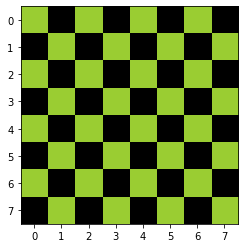

In [53]:
a = np.zeros((8, 8, 3), dtype=np.uint8)
yellow_green = [154, 205, 50]
a[::2, ::2] = yellow_green
a[1::2, 1::2] = yellow_green
plt.imshow(a)
plt.xticks(range(8))
plt.yticks(range(8));

## 3. Tính toán trên Numpy array 

Để sử dụng Numpy hiệu quả thì thay đổi cách tư duy: cần suy nghĩ về <font color=blue>các thao tác tính toán trên nguyên mảng</font> mà Numpy đã cung cấp, chứ không phải là các thao tác tính toán trên từng con số

Hầu hết mọi thao tác tính toán trên mảng mà ta có thể nghĩ tới thì đều đã được Numpy cung cấp:

| Tư duy vòng lặp | Tư duy mảng |
|---|---|
| `for` + tính toán | ufunc: `+ - * / ** np.exp np.log …` |
| `for` + cộng dồn | các phép rút gọn (reduction) với `axis`: `sum mean min max std` |
| `if` (lọc) | mặt nạ boolean (boolean mask) |
| `if / else` | `np.where`, `np.select` |
| đếm | `np.unique(return_counts=True)`, `np.bincount` |
| sắp xếp theo khóa | `argsort`, `argpartition` |

Hầu hết các thao tác đều có ở dạng hàm **và** dạng phương thức: `np.mean(a)` = `a.mean()`. Dùng cách nào dễ đọc hơn.

### 3.1 Nhìn qua dữ liệu: có gì bất thường không?

`axis` = chiều sẽ **biến mất**. `axis=0` gộp các dòng lại → mỗi cột cho ra một giá trị.

min : [0. 0. 0. 0. 0.]
max : [10. 10. 10. 10. 10.]


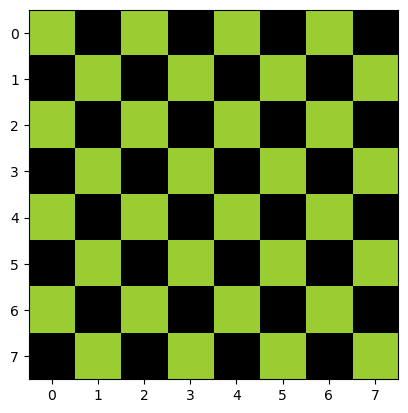

In [54]:
# Tính min, max của mỗi cột điểm
# để xem có gì bất thường không
print("min :", p4ds_grades.min(axis=0))
print("max :", p4ds_grades.max(axis=0))

In [55]:
# Các dòng đáng ngờ: sinh viên có ít nhất một bài tập bị 0 điểm
hw = p4ds_grades[:, :3]
has_zero_hw = (hw == 0).any(axis=1)# mỗi sinh viên một giá trị True/False
print("số sinh viên có bài tập 0 điểm:", has_zero_hw.sum())
p4ds_grades[has_zero_hw]

số sinh viên có bài tập 0 điểm: 5


array([[0.  , 0.  , 0.  , 0.  , 0.  ],
       [8.5 , 8.25, 0.  , 0.  , 2.79],
       [0.  , 9.  , 9.55, 6.5 , 6.34],
       [0.  , 9.75, 0.  , 8.5 , 5.88],
       [0.  , 8.5 , 9.6 , 9.  , 7.52]])

Dòng 0 toàn số 0: có lẽ là một sinh viên đã đăng ký nhưng không tham gia học. Khi phân tích thật, bạn phải quyết định (và **ghi lại**) có loại những dòng như vậy hay không. Ở đây ta giữ lại, nhưng ghi chú điều này.

### 3.2 Điểm tổng kết: tổng có trọng số chính là tích vô hướng

In [56]:
# Tính cột điểm tổng kết
avg_grades = (p4ds_grades[:, 0] * 0.5 / 3 
              + p4ds_grades[:, 1] * 0.5 / 3
              + p4ds_grades[:, 2] * 0.5 / 3
              + p4ds_grades[:, 3] * 0.5)
avg_grades.round(2)

array([ 0.  ,  9.75,  8.21,  8.89,  9.42,  9.25,  9.46,  9.37,  9.35,
        8.93,  8.44,  9.  ,  7.54,  8.88,  9.12, 10.  ,  2.79,  9.48,
        9.32,  9.46,  9.83,  9.96,  7.33,  9.67,  8.67,  9.36,  8.75,
        9.62,  8.36,  6.42,  9.17,  9.33,  8.39,  8.5 ,  8.25,  6.34,
        8.12,  8.24,  5.88,  8.13,  9.5 ,  9.  , 10.  ,  7.52,  8.92])

Công thức trên chính là $\text{avg_grades} = X\,w$, trong đó $w$ chứa các trọng số. Chỉ một dòng code, và khi đổi chính sách tính điểm thì chỉ cần sửa một mảng.

In [57]:
X = p4ds_grades[:, :4]
weights = np.array([0.5 / 3, 0.5 / 3, 0.5 / 3, 0.5])
assert np.isclose(weights.sum(), 1.0)          # kiểm tra nhanh: tổng trọng số là 100%

final = X @ weights                            # (45, 4) @ (4,) -> (45,)
print(final.shape)
print("giống bản viết dài?", np.allclose(final, avg_grades))

(45,)
giống bản viết dài? True


**Đối chiếu với điểm chính thức** (cột `p4ds_grades[:,4]`):

In [62]:
official = p4ds_grades[:, 4]
print("bằng nhau tuyệt đối (==)     :", (final == official).sum(), "/", len(final))
print("bằng nhau sau khi làm tròn 2 :", (np.round(final, 2) == official).sum(), "/", len(final))
print("xấp xỉ bằng (atol=0.005)     :", np.isclose(final, official, atol=0.005).sum(), "/", len(final))

bằng nhau tuyệt đối (==)     : 12 / 45
bằng nhau sau khi làm tròn 2 : 44 / 45
xấp xỉ bằng (atol=0.005)     : 44 / 45


Chỉ vài giá trị khớp khi so bằng `==`. Công thức của ta sai sao? Không: cột chính thức đã được **làm tròn 2 chữ số thập phân**, và số thực dấu chấm động (floating-point) cũng hiếm khi bằng nhau tuyệt đối. Không bao giờ dùng `==` với số thực; hãy so sánh với một sai số cho phép (tolerance).

### 3.3 Mặt nạ (mask): lọc và đếm

In [59]:
# Tỉ lệ SV rớt môn là bao nhiêu?
# np.sum(avg_grades < 5) / len(avg_grades)
np.mean(avg_grades < 5)

0.044444444444444446

In [60]:
# Hãy tìm các SV có điểm số lớn hơn 9.
# Xuất ra điểm số
avg_grades[avg_grades > 9]

array([ 9.75      ,  9.41666667,  9.25      ,  9.45833333,  9.36666667,
        9.35      ,  9.125     , 10.        ,  9.48333333,  9.325     ,
        9.45833333,  9.83333333,  9.95833333,  9.66666667,  9.35833333,
        9.625     ,  9.16666667,  9.33333333,  9.5       , 10.        ])

In [61]:
# Hãy tìm các SV có điểm số lớn hơn 9.
# Xuất ra vị trí
np.argwhere(avg_grades > 9).reshape(-1)

array([ 1,  4,  5,  6,  7,  8, 14, 15, 17, 18, 19, 20, 21, 23, 25, 27, 30,
       31, 40, 42])

### 3.4 `if / else` trên nguyên mảng: `np.where` và `np.select`

**Bài toán:** từ điểm tổng kết `final` của 45 sinh viên

1. Gắn nhãn **đậu / rớt** cho từng sinh viên (đậu nếu điểm ≥ 5)

In [63]:
# Gắn nhãn đậu / rớt cho từng sinh viên (đậu nếu điểm ≥ 5)
status = np.where(final >= 5, "đậu", "rớt")
print(status[:8])

['rớt' 'đậu' 'đậu' 'đậu' 'đậu' 'đậu' 'đậu' 'đậu']


2. Quy đổi sang **điểm chữ** theo thang sau:

| Điểm chữ | Điều kiện |
|---|---|
| A | `final` ≥ 8.5 |
| B | 7.0 ≤ `final` < 8.5 |
| C | 5.5 ≤ `final` < 7.0 |
| D | 4.0 ≤ `final` < 5.5 |
| F | `final` < 4.0 |

In [64]:
conditions = [final >= 8.5, final >= 7.0, final >= 5.5, final >= 4.0]
letters    = ["A",          "B",          "C",          "D"]
letter = np.select(conditions, letters, default="F") # điều kiện True đầu tiên sẽ được chọn
letter

array(['F', 'A', 'B', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'B', 'A', 'B',
       'A', 'A', 'A', 'F', 'A', 'A', 'A', 'A', 'A', 'B', 'A', 'A', 'A',
       'A', 'A', 'B', 'C', 'A', 'A', 'B', 'A', 'B', 'C', 'B', 'B', 'C',
       'B', 'A', 'A', 'A', 'B', 'A'], dtype='<U1')

3. Đếm số sinh viên ở mỗi điểm chữ.

In [83]:
values, counts = np.unique(letter, return_counts=True)
dict(zip(values.tolist(), counts.tolist()))

{'A': 29, 'B': 11, 'C': 3, 'F': 2}

### 3.5 Thống kê mô tả

In [66]:
# Tính mean & standard deviation của cột điểm tổng kết
print("mean:", p4ds_grades.mean(axis=0).round(2))
print("std:", p4ds_grades.std(axis=0).round(2))

mean: [8.73 9.33 8.86 7.91 8.44]
std: [3.01 1.61 2.55 2.   1.81]


In [67]:
# Tính min, lower quartile, median, upper quartile, max 
# của cột điểm tổng kết
print(np.percentile(avg_grades, 0))
print(np.percentile(avg_grades, 25))
print(np.percentile(avg_grades, 50))
print(np.percentile(avg_grades, 75))
print(np.percentile(avg_grades, 100))

0.0
8.241666666666667
8.933333333333334
9.416666666666668
10.0


### 3.6 Histogram

In [69]:
bins = np.arange(11)

# Tìm index (bin) cho từng giá trị
i = np.searchsorted(bins, final,side='right')-1
i = np.clip(i, 0, 9) 
i

array([0, 9, 8, 8, 9, 9, 9, 9, 9, 8, 8, 9, 7, 8, 9, 9, 2, 9, 9, 9, 9, 9,
       7, 9, 8, 9, 8, 9, 8, 6, 9, 9, 8, 8, 8, 6, 8, 8, 5, 8, 9, 9, 9, 7,
       8])

In [70]:
# Cách làm sai: counts[i] += 1
counts_wrong = np.zeros(10, dtype=int)
counts_wrong[i] += 1     # chỉ số lặp lại chỉ được cộng MỘT lần
counts_wrong

array([1, 0, 1, 0, 0, 1, 1, 1, 1, 1])

In [71]:
# Cách 1: np.add.at xử lý đúng các chỉ số lặp lại
counts_at = np.zeros(10, dtype=int)
np.add.at(counts_at, i, 1)
counts_at

array([ 1,  0,  1,  0,  0,  1,  2,  3, 15, 22])

In [72]:
# Cách 2: bincount (cách chuẩn để "đếm theo nhãn số nguyên")
counts_bc = np.bincount(i, minlength=10)
counts_bc

array([ 1,  0,  1,  0,  0,  1,  2,  3, 15, 22])

In [73]:
# Cách 3: hàm có sẵn của thư viện
counts_np, _ = np.histogram(final, bins=bins)
counts_np

array([ 1,  0,  1,  0,  0,  1,  2,  3, 15, 22])

In [74]:
assert np.array_equal(counts_at, counts_bc) and np.array_equal(counts_at, counts_np)
print("cả ba cách đều khớp, tổng là", counts_np.sum(), "= số sinh viên")

cả ba cách đều khớp, tổng là 45 = số sinh viên


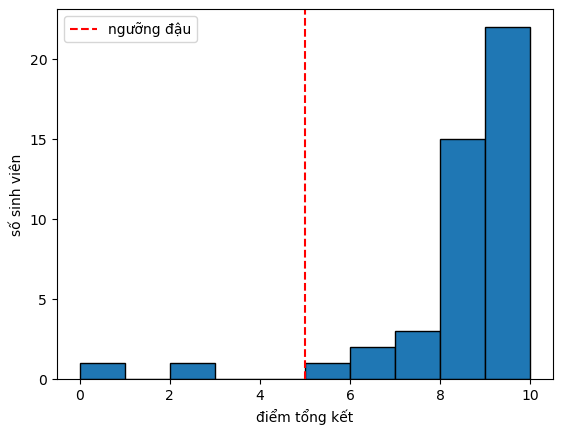

In [79]:
plt.hist(final, bins=bins, edgecolor="black")
plt.axvline(5, color="red", linestyle="--", label="ngưỡng đậu")
plt.xlabel("điểm tổng kết"); plt.ylabel("số sinh viên"); plt.legend();

### 3.7 Xếp hạng: top-k sinh viên

In [76]:
# Lấy ra 5 SV có điểm tổng kết cao nhất
order = np.argsort(final)[::-1]
print("5 dòng cao nhất :", order[:5])
print("5 điểm cao nhất :", final[order[:5]].round(2))

5 dòng cao nhất : [42 15 21 20  1]
5 điểm cao nhất : [10.   10.    9.96  9.83  9.75]


In [81]:
# Khi chỉ cần k giá trị lớn nhất, argpartition không cần sắp xếp toàn bộ: O(n) thay vì O(n log n)
k = 5
top_k = np.argpartition(final, -k)[::-1]      # k giá trị lớn nhất, không theo thứ tự
top_k[:5]

array([20, 15, 42, 21,  1])

### 3.8 Lưu kết quả

In [82]:
report = np.concatenate([X, final.reshape(-1, 1)], axis=1)     
np.savetxt("Data/P4DS-Grades-Report.csv", report, delimiter=",", fmt="%.2f",
           header="HW1,HW2,HW3,Project,Final_computed", comments="")

Ta ghi ra một file **mới**. Nếu ghi đè lên file dữ liệu gốc, sẽ không ai chạy lại được phân tích này.